In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import energyflow as ef
from energyflow.utils import gen_massless_phase_space
from energyflow import EFPSet
import os
import glob
import time
from RegressFunctions import *
from RestrictedEFPs import efps_chunked
from PhysicsFunctions import *
from scipy.special import gammaln, digamma, polygamma, zeta
from scipy.interpolate import UnivariateSpline
from scipy.optimize import brentq

os.makedirs('figures', exist_ok=True)

## Import $Q$-vectors, Thrust 

In [2]:
labels = {'Z': r'$Z\to q\bar q$', 
          'Z1': r'$Z\to q\bar q$, 1 splitting', 
        #   'Z2': r'$Z\to q\bar q$, 2 splittings',
        #   'Z3': r'$Z\to q\bar q$, 3 splittings', 'Z4': r'$Z\to q\bar q$, 4 splittings',
          'Z1_500GeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 500$ GeV', 
          'Z1_1TeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 1$ TeV',
          'Z1_fix08': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.08$',
          'Z1_fix12': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.12$',
          'Z1_fix16': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.16$',
          }

In [4]:
#########################################################
### Load features (computed in make_features.ipynb)
#########################################################

QVC_sets = {k: np.load(f'features/QVEC_nq2048_{k}.npy', mmap_mode='r') for k in labels if os.path.exists(f'features/QVEC_nq2048_{k}.npy')}
print('Qvc:', {k: v.shape for k, v in QVC_sets.items()}, '  missing:', [k for k in labels if k not in QVC_sets])

#########################################################
### Load targets (computed in Make_Features.ipynb)
#########################################################
thrusts = {k: np.load(f'features/TARGETS_{k}.npz')['thrust'] for k in labels if os.path.exists(f'features/TARGETS_{k}.npz')}
print('thrust:', {k: v.shape for k, v in thrusts.items()}, '  missing:', [k for k in labels if k not in thrusts])

Qvc: {'Z': (100000, 2048), 'Z1': (99387, 2048), 'Z1_500GeV': (100000, 2048), 'Z1_1TeV': (100000, 2048), 'Z1_fix08': (73394, 2048), 'Z1_fix12': (86070, 2048), 'Z1_fix16': (92872, 2048)}   missing: []
thrust: {'Z': (100000,), 'Z1': (99387,), 'Z1_500GeV': (100000,), 'Z1_1TeV': (100000,), 'Z1_fix08': (73394,), 'Z1_fix12': (86070,), 'Z1_fix16': (92872,)}   missing: []


## Regress $Q \rightarrow$ Thrust with KRR 

In [7]:
## train on QVC_sets --> regress to thrusts ... better on gpu 
λs = [1e-10]
Ps = np.unique(np.round(np.logspace(0, 3.5, 10)).astype(int))   
n_reps = lambda P: max(int(500 / P), 5)
KRR_NTK_losses = {λ: {} for λ in λs}
for λ in λs: 
    for label in labels: 
        KRR_NTK_losses[λ][label] = run_regression_sweep(QVC_sets[label], thrusts[label],  Ps, λ=λ, n_repeats=n_reps, test_size=0.2, 
                                        w_true=None, filter_zero_var=True, center=True, scale=True, kern="NTK")


(80000, 1967) (20000, 1967) 51.2 GB per train Gram
       1  |  0.002782
       2  |  0.002125
       6  |  0.001306
      15  |  0.000438
      36  |  0.000363
      88  |  0.000210
     215  |  0.000186
     527  |  0.000127
    1292  |  0.000103
    3162  |  0.000092
(79509, 1365) (19878, 1365) 50.6 GB per train Gram
       1  |  0.002085
       2  |  0.001603
       6  |  0.000895
      15  |  0.000188
      36  |  0.000117
      88  |  0.000017
     215  |  0.000012
     527  |  0.000002
    1292  |  0.000001
    3162  |  0.000000
(80000, 1365) (20000, 1365) 51.2 GB per train Gram
       1  |  0.001866
       2  |  0.001544
       6  |  0.000813
      15  |  0.000397
      36  |  0.000110
      88  |  0.000020
     215  |  0.000011
     527  |  0.000002
    1292  |  0.000001
    3162  |  0.000000
(80000, 1365) (20000, 1365) 51.2 GB per train Gram
       1  |  0.001813
       2  |  0.001471
       6  |  0.000861
      15  |  0.000473
      36  |  0.000126
      88  |  0.000046
    

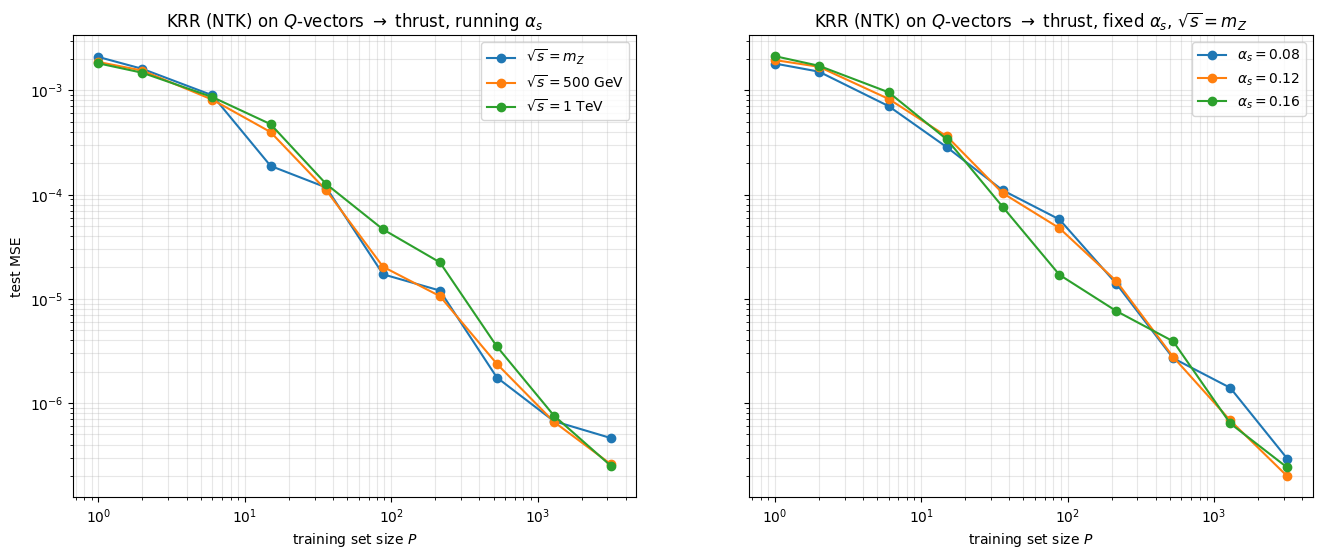

In [9]:
λ = 1e-10
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

ax1.loglog(Ps, KRR_NTK_losses[λ]['Z1'][0], 'o-', color='C0', label=r'$\sqrt{s} = m_Z$')
ax1.loglog(Ps, KRR_NTK_losses[λ]['Z1_500GeV'][0], 'o-', color='C1', label=r'$\sqrt{s} = 500$ GeV')
ax1.loglog(Ps, KRR_NTK_losses[λ]['Z1_1TeV'][0], 'o-', color='C2', label=r'$\sqrt{s} = 1$ TeV')
ax1.set_title(r'KRR (NTK) on $Q$-vectors $\to$ thrust, running $\alpha_s$'); ax1.set_xlabel('training set size $P$'); ax1.set_ylabel('test MSE')
ax1.legend(); ax1.grid(True, which='both', alpha=0.3)

ax2.loglog(Ps, KRR_NTK_losses[λ]['Z1_fix08'][0], 'o-', color='C0', label=r'$\alpha_s = 0.08$')
ax2.loglog(Ps, KRR_NTK_losses[λ]['Z1_fix12'][0], 'o-', color='C1', label=r'$\alpha_s = 0.12$')
ax2.loglog(Ps, KRR_NTK_losses[λ]['Z1_fix16'][0], 'o-', color='C2', label=r'$\alpha_s = 0.16$')
ax2.set_title(r'KRR (NTK) on $Q$-vectors $\to$ thrust, fixed $\alpha_s$, $\sqrt{s} = m_Z$'); ax2.set_xlabel('training set size $P$')
ax2.legend(); ax2.grid(True, which='both', alpha=0.3)

## Regress $Q \rightarrow$ Thrust with NN